# Qwen Priority-One Analysis: Reconstructed Full-Context Replay

This notebook completes the pending Qwen analyses for the TAE paper:

- five primary classifier evaluations;
- later-record prompt-bootstrap confidence intervals;
- paired full-context versus archived completion-only comparisons;
- coefficient stability and fold overlap;
- record-level H1–H4 permutation tests;
- prompt-aware conditional and sign-flip tests;
- prompt-token and 250-key-window sensitivity analyses;
- leave-one-domain-out evaluation;
- a synthetic downstream-analysis positive control;
- feature-space comparison, figures, tables, a result memo, and a downloadable ZIP.

**Inputs**

1. `qwen_compact_analysis_bundle.zip`
2. `point3_qwen_structural_features.npz`

The notebook finds these automatically in Kaggle Inputs, `/kaggle/working`, or `/mnt/data`.

**Runtime**

Full mode uses 10,000 record-level permutations, 100,000 prompt-aware permutations, and 2,000 prompt bootstraps. For a quick smoke test only, set the Kaggle environment variable `FAST_MODE=1` before running.

**Interpretive boundary**

This is reconstructed full-context teacher-forced replay, not literal generation-time activation recovery. Original generated token IDs and exact model/tokenizer revisions were not archived, so the paired comparison is not a pure causal estimate of prompt context. The synthetic positive control validates the downstream analysis code only; a task-based extraction positive control remains a separate experiment.

## 1. Configuration, utilities, and statistical functions

In [1]:
from __future__ import annotations

import hashlib
import itertools
import json
import math
import os
import platform
import shutil
import sys
import warnings
import zipfile
from collections import Counter
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEED = 42
N_SPLITS = 5
CLASSIFIER_C = 0.01
FAST_MODE = bool(int(os.environ.get("FAST_MODE", "0")))
N_RECORD_PERMUTATIONS = 1_000 if FAST_MODE else 10_000
N_PROMPT_PERMUTATIONS = 5_000 if FAST_MODE else 100_000
N_BOOTSTRAPS = 500 if FAST_MODE else 2_000

FULL_CONTEXT_ZIP_NAME = "qwen_compact_analysis_bundle.zip"
COMPLETION_ONLY_NAME = "point3_qwen_structural_features.npz"

WORK_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("/mnt/data")
OUTPUT_DIR = WORK_ROOT / "qwen_priority1_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)


def show(obj):
    try:
        from IPython.display import display
        display(obj)
    except Exception:
        print(obj)


def find_file(filename: str) -> Path | None:
    roots = [Path("/kaggle/input"), Path("/kaggle/working"), Path("/mnt/data"), Path.cwd()]
    matches: list[Path] = []
    for root in roots:
        if root.exists():
            matches.extend(root.rglob(filename))
    matches = sorted(set(matches), key=lambda p: (len(str(p)), str(p)))
    return matches[0] if matches else None


def sha256_file(path: Path, block_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def baseline_pipeline() -> Pipeline:
    return Pipeline([
        ("scale", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                C=CLASSIFIER_C,
                random_state=SEED,
            ),
        ),
    ])


def metric_dict(y_true: np.ndarray, probabilities: np.ndarray, predictions: np.ndarray) -> dict:
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)),
    }


def make_splits(y_values: np.ndarray, groups: np.ndarray | None = None, design: str = "instance"):
    if design == "instance":
        cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
        return list(cv.split(np.zeros((len(y_values), 1)), y_values))
    if design == "prompt_grouped":
        if groups is None:
            raise ValueError("groups are required for prompt-grouped CV")
        cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
        return list(cv.split(np.zeros((len(y_values), 1)), y_values, groups=groups))
    raise ValueError(f"Unknown design: {design}")


def evaluate_oof_with_splits(X: np.ndarray, y_values: np.ndarray, splits):
    probabilities = np.full(len(y_values), np.nan, dtype=float)
    predictions = np.full(len(y_values), -1, dtype=int)
    fold_ids = np.full(len(y_values), -1, dtype=int)
    fold_rows = []

    for fold, (train_idx, test_idx) in enumerate(splits):
        model = baseline_pipeline()
        model.fit(X[train_idx], y_values[train_idx])
        fold_probabilities = model.predict_proba(X[test_idx])[:, 1]
        fold_predictions = model.predict(X[test_idx])
        probabilities[test_idx] = fold_probabilities
        predictions[test_idx] = fold_predictions
        fold_ids[test_idx] = fold
        row = metric_dict(y_values[test_idx], fold_probabilities, fold_predictions)
        row.update({
            "fold": fold,
            "n_train": int(len(train_idx)),
            "n_test": int(len(test_idx)),
            "test_corrections": int(y_values[test_idx].sum()),
        })
        fold_rows.append(row)

    if np.isnan(probabilities).any() or np.any(predictions < 0):
        raise RuntimeError("OOF predictions are incomplete")

    return {
        "metrics": metric_dict(y_values, probabilities, predictions),
        "probabilities": probabilities,
        "predictions": predictions,
        "fold_ids": fold_ids,
        "fold_metrics": pd.DataFrame(fold_rows),
    }


def evaluate_train_test(X: np.ndarray, y_values: np.ndarray, train_mask: np.ndarray, test_mask: np.ndarray):
    train_idx = np.where(train_mask)[0]
    test_idx = np.where(test_mask)[0]
    model = baseline_pipeline()
    model.fit(X[train_idx], y_values[train_idx])
    probabilities = model.predict_proba(X[test_idx])[:, 1]
    predictions = model.predict(X[test_idx])
    return {
        "metrics": metric_dict(y_values[test_idx], probabilities, predictions),
        "probabilities": probabilities,
        "predictions": predictions,
        "train_idx": train_idx,
        "test_idx": test_idx,
        "model": model,
    }


def prompt_bootstrap_auc(y_true, probabilities, groups, n_bootstraps=N_BOOTSTRAPS, seed=SEED):
    rng = np.random.default_rng(seed)
    unique_groups = np.unique(groups)
    group_to_indices = {group: np.where(groups == group)[0] for group in unique_groups}
    scores = []
    for _ in range(n_bootstraps):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        sampled_indices = np.concatenate([group_to_indices[group] for group in sampled_groups])
        sampled_y = y_true[sampled_indices]
        if len(np.unique(sampled_y)) < 2:
            continue
        scores.append(roc_auc_score(sampled_y, probabilities[sampled_indices]))
    scores = np.asarray(scores, dtype=float)
    return {
        "n_requested": int(n_bootstraps),
        "n_scored": int(len(scores)),
        "ci_low": float(np.quantile(scores, 0.025)),
        "median": float(np.quantile(scores, 0.5)),
        "ci_high": float(np.quantile(scores, 0.975)),
        "scores": scores,
    }


def paired_prompt_bootstrap_auc_difference(
    y_true, probabilities_a, probabilities_b, groups, n_bootstraps=N_BOOTSTRAPS, seed=SEED
):
    rng = np.random.default_rng(seed)
    unique_groups = np.unique(groups)
    group_to_indices = {group: np.where(groups == group)[0] for group in unique_groups}
    differences = []
    for _ in range(n_bootstraps):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        sampled_indices = np.concatenate([group_to_indices[group] for group in sampled_groups])
        sampled_y = y_true[sampled_indices]
        if len(np.unique(sampled_y)) < 2:
            continue
        auc_a = roc_auc_score(sampled_y, probabilities_a[sampled_indices])
        auc_b = roc_auc_score(sampled_y, probabilities_b[sampled_indices])
        differences.append(auc_a - auc_b)
    differences = np.asarray(differences, dtype=float)
    return {
        "n_requested": int(n_bootstraps),
        "n_scored": int(len(differences)),
        "difference_mean": float(differences.mean()),
        "ci_low": float(np.quantile(differences, 0.025)),
        "median": float(np.quantile(differences, 0.5)),
        "ci_high": float(np.quantile(differences, 0.975)),
        "probability_difference_gt_zero": float(np.mean(differences > 0)),
        "differences": differences,
    }


def bh_adjust(p_values: np.ndarray) -> np.ndarray:
    p_values = np.asarray(p_values, dtype=float)
    n_tests = len(p_values)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted_ranked = ranked * n_tests / np.arange(1, n_tests + 1)
    adjusted_ranked = np.minimum.accumulate(adjusted_ranked[::-1])[::-1]
    adjusted = np.empty(n_tests, dtype=float)
    adjusted[order] = np.clip(adjusted_ranked, 0, 1)
    return adjusted


def flat_head_to_layer_head(flat_index: int, n_heads: int = 12) -> dict:
    return {"flat_index": int(flat_index), "layer": int(flat_index // n_heads), "head": int(flat_index % n_heads)}


def feature_block_counts(indices: np.ndarray, heads_per_family: int = 336) -> dict:
    indices = np.asarray(indices)
    boundaries = {
        "H1": (0, heads_per_family),
        "H2": (heads_per_family, 2 * heads_per_family),
        "H3": (2 * heads_per_family, 3 * heads_per_family),
        "H4": (3 * heads_per_family, 3 * heads_per_family + 1),
    }
    return {
        name: int(np.sum((indices >= lo) & (indices < hi)))
        for name, (lo, hi) in boundaries.items()
    }


def coefficient_stability(X: np.ndarray, y_values: np.ndarray, groups=None, design: str = "instance"):
    splits = make_splits(y_values, groups=groups, design=design)
    coefficients = []
    training_sets = []

    for train_idx, _ in splits:
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[train_idx])
        classifier = LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            C=CLASSIFIER_C,
            random_state=SEED,
        )
        classifier.fit(X_train, y_values[train_idx])
        coefficients.append(classifier.coef_[0].copy())
        training_sets.append(set(train_idx.tolist()))

    coefficients = np.asarray(coefficients)
    correlation_matrix = np.corrcoef(coefficients)
    pairwise_correlations = np.asarray([
        correlation_matrix[i, j]
        for i in range(N_SPLITS)
        for j in range(i + 1, N_SPLITS)
    ])

    signs = np.sign(coefficients)
    unanimous = np.all(signs == signs[0], axis=0)
    mean_absolute = np.abs(coefficients).mean(axis=0)
    stable_strong = unanimous & (mean_absolute > np.percentile(mean_absolute, 95))
    stable_indices = np.where(stable_strong)[0]

    overlaps = []
    for i in range(N_SPLITS):
        for j in range(i + 1, N_SPLITS):
            intersection = len(training_sets[i] & training_sets[j])
            smaller = min(len(training_sets[i]), len(training_sets[j]))
            overlaps.append(intersection / smaller)

    return {
        "mean_pairwise_correlation": float(pairwise_correlations.mean()),
        "pairwise_correlation_sd": float(pairwise_correlations.std()),
        "unanimous_sign_count": int(unanimous.sum()),
        "unanimous_sign_fraction": float(unanimous.mean()),
        "stable_strong_count": int(stable_strong.sum()),
        "stable_strong_indices": stable_indices,
        "mean_training_overlap": float(np.mean(overlaps)),
        "training_sizes": [len(x) for x in training_sets],
        "coefficient_matrix": coefficients,
        "correlation_matrix": correlation_matrix,
    }


def monte_carlo_mean_difference_tests(
    X_features: np.ndarray,
    y_values: np.ndarray,
    n_permutations: int = N_RECORD_PERMUTATIONS,
    seed: int = SEED,
    batch_size: int = 500,
):
    """Two-sided Monte Carlo permutation tests for correction minus non-corrective means."""
    X_features = np.asarray(X_features, dtype=np.float64)
    y_values = np.asarray(y_values, dtype=int)
    positive = y_values == 1
    negative = ~positive
    n_positive = int(positive.sum())
    n_negative = int(negative.sum())
    observed = X_features[positive].mean(axis=0) - X_features[negative].mean(axis=0)
    total_sum = X_features.sum(axis=0)
    exceedances = np.zeros(X_features.shape[1], dtype=np.int64)
    rng = np.random.default_rng(seed)

    completed = 0
    while completed < n_permutations:
        current = min(batch_size, n_permutations - completed)
        random_scores = rng.random((current, len(y_values)), dtype=np.float64)
        selected = np.argpartition(random_scores, kth=n_positive - 1, axis=1)[:, :n_positive]
        assignment = np.zeros((current, len(y_values)), dtype=np.float64)
        assignment[np.arange(current)[:, None], selected] = 1.0
        positive_sums = assignment @ X_features
        null_difference = (
            positive_sums / n_positive
            - (total_sum - positive_sums) / n_negative
        )
        exceedances += np.sum(
            np.abs(null_difference) >= np.abs(observed)[None, :] - 1e-12,
            axis=0,
        )
        completed += current

    p_values = (1 + exceedances) / (n_permutations + 1)
    return observed, p_values


def mixed_prompt_structure(y_values: np.ndarray, groups: np.ndarray):
    output = []
    for prompt in np.unique(groups):
        indices = np.where(groups == prompt)[0]
        prompt_y = y_values[indices]
        if len(np.unique(prompt_y)) > 1:
            output.append((str(prompt), indices, int(prompt_y.sum())))
    return output


def enumerate_binary_assignments(group_size: int, correction_count: int) -> np.ndarray:
    rows = []
    for correction_positions in itertools.combinations(range(group_size), correction_count):
        row = np.zeros(group_size, dtype=np.float64)
        row[list(correction_positions)] = 1
        rows.append(row)
    return np.vstack(rows)


def build_conditional_label_matrix(
    y_values: np.ndarray,
    groups: np.ndarray,
    n_permutations: int = N_PROMPT_PERMUTATIONS,
    seed: int = SEED,
    exact_threshold: int = 50_000,
):
    mixed_groups = mixed_prompt_structure(y_values, groups)
    if not mixed_groups:
        raise RuntimeError("No mixed-class prompts are available")

    mixed_indices = []
    slices = []
    offset = 0
    for prompt, indices, correction_count in mixed_groups:
        mixed_indices.extend(indices.tolist())
        slices.append((offset, offset + len(indices), correction_count, prompt))
        offset += len(indices)

    mixed_indices = np.asarray(mixed_indices, dtype=int)
    total_assignments = math.prod(
        comb(end - start, correction_count)
        for start, end, correction_count, _ in slices
    )
    exact = total_assignments <= exact_threshold

    if exact:
        group_assignments = [
            enumerate_binary_assignments(end - start, correction_count)
            for start, end, correction_count, _ in slices
        ]
        rows = []
        for combination in itertools.product(*[range(len(a)) for a in group_assignments]):
            rows.append(np.concatenate([
                group_assignments[group_index][assignment_index]
                for group_index, assignment_index in enumerate(combination)
            ]))
        label_matrix = np.vstack(rows)
    else:
        rng = np.random.default_rng(seed)
        label_matrix = np.zeros((n_permutations, len(mixed_indices)), dtype=np.float32)
        for start, end, correction_count, _ in slices:
            group_size = end - start
            random_scores = rng.random((n_permutations, group_size))
            selected = np.argpartition(
                random_scores,
                kth=correction_count - 1,
                axis=1,
            )[:, :correction_count]
            rows = np.arange(n_permutations)[:, None]
            label_matrix[rows, start + selected] = 1.0

    for start, end, correction_count, _ in slices:
        label_matrix[:, start:end] -= correction_count / (end - start)

    return {
        "label_matrix": label_matrix,
        "mixed_indices": mixed_indices,
        "slices": slices,
        "mixed_prompts": [prompt for _, _, _, prompt in slices],
        "total_assignments": int(total_assignments),
        "exact": exact,
    }


def prompt_centered_conditional_tests(
    X_features: np.ndarray,
    y_values: np.ndarray,
    groups: np.ndarray,
    heads_per_family: int = 336,
    n_heads: int = 12,
):
    design = build_conditional_label_matrix(y_values, groups)
    mixed_indices = design["mixed_indices"]
    X_mixed = X_features[mixed_indices].copy()
    y_mixed = y_values[mixed_indices].astype(np.float64).copy()

    for start, end, correction_count, _ in design["slices"]:
        X_mixed[start:end] -= X_mixed[start:end].mean(axis=0, keepdims=True)
        y_mixed[start:end] -= correction_count / (end - start)

    observed_statistic = y_mixed @ X_mixed
    label_matrix = design["label_matrix"]
    denominator = len(label_matrix)
    family_results = {}

    for family_index, family in enumerate(("H1", "H2", "H3")):
        lo = family_index * heads_per_family
        hi = (family_index + 1) * heads_per_family
        null_statistics = label_matrix @ X_mixed[:, lo:hi]
        observed = observed_statistic[lo:hi]
        exceedances = np.sum(
            np.abs(null_statistics) >= np.abs(observed)[None, :] - 1e-12,
            axis=0,
        )
        p_values = (
            exceedances / denominator
            if design["exact"]
            else (1 + exceedances) / (denominator + 1)
        )
        adjusted = bh_adjust(p_values)
        best = int(np.argmin(p_values))
        location = flat_head_to_layer_head(best, n_heads)
        family_results[family] = {
            "raw_p_lt_0_05": int(np.sum(p_values < 0.05)),
            "best_raw_p": float(p_values[best]),
            "best_adjusted_p": float(adjusted.min()),
            "fdr_significant_heads": int(np.sum(adjusted < 0.05)),
            "best_layer": location["layer"],
            "best_head": location["head"],
        }

    h4_null = label_matrix @ X_mixed[:, -1]
    h4_observed = observed_statistic[-1]
    h4_exceedances = int(np.sum(np.abs(h4_null) >= abs(h4_observed) - 1e-12))
    h4_p = (
        h4_exceedances / denominator
        if design["exact"]
        else (1 + h4_exceedances) / (denominator + 1)
    )

    return {
        "mixed_prompts": design["mixed_prompts"],
        "mixed_prompt_count": len(design["mixed_prompts"]),
        "mixed_record_count": int(len(mixed_indices)),
        "total_possible_assignments": design["total_assignments"],
        "exact": design["exact"],
        "null_assignments_used": int(denominator),
        "families": family_results,
        "h4_p_value": float(h4_p),
    }


def exact_prompt_level_sign_flip(
    X_features: np.ndarray,
    y_values: np.ndarray,
    groups: np.ndarray,
    heads_per_family: int = 336,
    n_heads: int = 12,
):
    prompt_differences = []
    mixed_prompts = []
    for prompt in np.unique(groups):
        indices = np.where(groups == prompt)[0]
        prompt_y = y_values[indices]
        if len(np.unique(prompt_y)) > 1:
            prompt_differences.append(
                X_features[indices][prompt_y == 1].mean(axis=0)
                - X_features[indices][prompt_y == 0].mean(axis=0)
            )
            mixed_prompts.append(str(prompt))

    differences = np.vstack(prompt_differences)
    n_prompts = len(mixed_prompts)
    if n_prompts > 20:
        raise RuntimeError("Too many mixed prompts for exact sign-flip enumeration")

    integers = np.arange(2 ** n_prompts, dtype=np.uint32)[:, None]
    bits = ((integers >> np.arange(n_prompts, dtype=np.uint32)) & 1).astype(np.float64)
    signs = 2 * bits - 1
    observed = differences.mean(axis=0)
    family_results = {}

    for family_index, family in enumerate(("H1", "H2", "H3")):
        lo = family_index * heads_per_family
        hi = (family_index + 1) * heads_per_family
        null = signs @ differences[:, lo:hi] / n_prompts
        family_observed = observed[lo:hi]
        p_values = np.mean(
            np.abs(null) >= np.abs(family_observed)[None, :] - 1e-12,
            axis=0,
        )
        adjusted = bh_adjust(p_values)
        best = int(np.argmin(p_values))
        location = flat_head_to_layer_head(best, n_heads)
        family_results[family] = {
            "raw_p_lt_0_05": int(np.sum(p_values < 0.05)),
            "best_raw_p": float(p_values[best]),
            "best_adjusted_p": float(adjusted.min()),
            "fdr_significant_heads": int(np.sum(adjusted < 0.05)),
            "best_layer": location["layer"],
            "best_head": location["head"],
        }

    h4_null = signs @ differences[:, -1] / n_prompts
    h4_p = float(np.mean(np.abs(h4_null) >= abs(observed[-1]) - 1e-12))
    return {
        "mixed_prompts": mixed_prompts,
        "mixed_prompt_count": n_prompts,
        "exact_sign_patterns": int(2 ** n_prompts),
        "families": family_results,
        "h4_p_value": h4_p,
        "mean_h4_correction_minus_noncorrective": float(observed[-1]),
    }



## 2. Load inputs, validate alignment, and run primary classifier analyses

In [2]:
print("=" * 72)
print("QWEN PRIORITY-ONE FULL ANALYSIS")
print("=" * 72)
print("FAST_MODE:", FAST_MODE)
print("Output directory:", OUTPUT_DIR)

# -----------------------------------------------------------------------------
# Environment
# -----------------------------------------------------------------------------
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
}
show(pd.DataFrame([environment]))


# -----------------------------------------------------------------------------
# Kaggle input discovery
#
# Kaggle may automatically extract an uploaded ZIP and expose its contents
# inside a folder named after the ZIP. This code first searches for the
# extracted files directly. It only opens the ZIP if necessary.
# -----------------------------------------------------------------------------
SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
    Path("/mnt/data"),
    Path.cwd(),
]

FULL_CONTEXT_ZIP_NAME = "qwen_compact_analysis_bundle.zip"
COMPLETION_ONLY_NAME = "point3_qwen_structural_features.npz"

BUNDLE_REQUIRED_FILES = {
    "qwen_compact_feature_manifest.json",
    "qwen_full_context_features.csv",
    "qwen_full_context_features.npz",
    "qwen_prompt_attention_features.npz",
}


def find_file(filename, roots=None):
    """Recursively locate a file, preferring /kaggle/input."""
    roots = roots or SEARCH_ROOTS
    matches = []

    for priority, root in enumerate(roots):
        if not root.exists():
            continue

        for path in root.rglob(filename):
            if path.is_file():
                matches.append((priority, path))

    if not matches:
        return None

    matches.sort(
        key=lambda item: (
            item[0],
            len(str(item[1])),
            str(item[1]),
        )
    )
    return matches[0][1]


def find_extracted_bundle_dir(roots=None):
    """
    Find a directory containing all required compact Qwen bundle files.

    This supports Kaggle's behavior of automatically exposing ZIP contents
    under a dataset folder.
    """
    roots = roots or SEARCH_ROOTS
    matches = []

    for priority, root in enumerate(roots):
        if not root.exists():
            continue

        for manifest_path in root.rglob(
            "qwen_compact_feature_manifest.json"
        ):
            candidate = manifest_path.parent

            if all(
                (candidate / filename).is_file()
                for filename in BUNDLE_REQUIRED_FILES
            ):
                matches.append((priority, candidate))

    if not matches:
        return None

    matches.sort(
        key=lambda item: (
            item[0],
            len(str(item[1])),
            str(item[1]),
        )
    )
    return matches[0][1]


# -----------------------------------------------------------------------------
# Locate the full-context bundle
# -----------------------------------------------------------------------------
DIRECT_BUNDLE_DIR = find_extracted_bundle_dir()
COMPLETION_ONLY_PATH = find_file(COMPLETION_ONLY_NAME)

if DIRECT_BUNDLE_DIR is not None:
    # Normal Kaggle Dataset behavior: files already exposed in a folder.
    EXTRACT_DIR = DIRECT_BUNDLE_DIR

    print("Full-context bundle directory:", EXTRACT_DIR)
    print(
        "Input mode: Kaggle-extracted directory "
        "(no unzip required)"
    )

else:
    # Fallback in case the original inner ZIP remains available.
    FULL_CONTEXT_ZIP = find_file(FULL_CONTEXT_ZIP_NAME)

    if FULL_CONTEXT_ZIP is None:
        raise FileNotFoundError(
            "Could not find the extracted Qwen compact bundle or "
            f"{FULL_CONTEXT_ZIP_NAME}.\n\n"
            "Expected these files together in one Kaggle input folder:\n"
            + "\n".join(
                f"  - {name}"
                for name in sorted(BUNDLE_REQUIRED_FILES)
            )
        )

    print("Full-context ZIP:", FULL_CONTEXT_ZIP)
    print("Input mode: ZIP fallback")

    LOCAL_EXTRACT_DIR = OUTPUT_DIR / "input_full_context"

    if LOCAL_EXTRACT_DIR.exists():
        shutil.rmtree(LOCAL_EXTRACT_DIR)

    LOCAL_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(FULL_CONTEXT_ZIP, "r") as archive:
        bad_member = archive.testzip()

        if bad_member is not None:
            raise RuntimeError(
                f"Corrupted ZIP member: {bad_member}"
            )

        archive.extractall(LOCAL_EXTRACT_DIR)

    EXTRACT_DIR = find_extracted_bundle_dir(
        roots=[LOCAL_EXTRACT_DIR]
    )

    if EXTRACT_DIR is None:
        raise FileNotFoundError(
            "The ZIP was extracted, but the four required bundle "
            "files were not found together in one directory."
        )


print(
    "Completion-only matrix:",
    COMPLETION_ONLY_PATH
    if COMPLETION_ONLY_PATH is not None
    else "NOT FOUND",
)


# -----------------------------------------------------------------------------
# Validate compact bundle contents
# -----------------------------------------------------------------------------
missing = {
    filename
    for filename in BUNDLE_REQUIRED_FILES
    if not (EXTRACT_DIR / filename).is_file()
}

if missing:
    raise FileNotFoundError(
        f"Missing bundle members in {EXTRACT_DIR}: "
        f"{sorted(missing)}"
    )


manifest_path = (
    EXTRACT_DIR / "qwen_compact_feature_manifest.json"
)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

for filename, expected_hash in manifest["files"].items():
    file_path = EXTRACT_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Manifest file is missing: {file_path}"
        )

    actual_hash = sha256_file(file_path)

    if actual_hash != expected_hash:
        raise RuntimeError(
            f"SHA-256 mismatch for {filename}: "
            f"expected {expected_hash}, got {actual_hash}"
        )

print("Bundle integrity and checksums: PASS")


# -----------------------------------------------------------------------------
# Load reconstructed-full-context feature matrices
# -----------------------------------------------------------------------------
with np.load(
    EXTRACT_DIR / "qwen_full_context_features.npz",
    allow_pickle=False,
) as archive:
    X_full = archive["X"].astype(np.float64)
    y = archive["y"].astype(int)
    labels = archive["labels"].astype(str)
    prompt_ids = archive["prompt_ids"].astype(str)
    source_indices = archive["source_indices"].astype(int)
    feature_names = archive["feature_names"].astype(str)


with np.load(
    EXTRACT_DIR / "qwen_prompt_attention_features.npz",
    allow_pickle=False,
) as archive:
    X_prompt_attention = archive[
        "X_prompt_attention"
    ].astype(np.float64)

    prompt_feature_names = archive[
        "feature_names"
    ].astype(str)

    prompt_source_indices = archive[
        "source_indices"
    ].astype(int)

    prompt_ids_check = archive[
        "prompt_ids"
    ].astype(str)


metadata = pd.read_csv(
    EXTRACT_DIR / "qwen_full_context_features.csv"
)

metadata = (
    metadata
    .sort_values("source_idx")
    .reset_index(drop=True)
)


# -----------------------------------------------------------------------------
# Validate record alignment
# -----------------------------------------------------------------------------
assert X_full.shape == (127, 1009), X_full.shape
assert X_prompt_attention.shape == (127, 336), (
    X_prompt_attention.shape
)

assert int(y.sum()) == 22
assert int((y == 0).sum()) == 105

assert np.array_equal(
    source_indices,
    np.arange(127),
)

assert np.array_equal(
    prompt_source_indices,
    source_indices,
)

assert np.array_equal(
    prompt_ids_check,
    prompt_ids,
)

assert np.isfinite(X_full).all()
assert np.isfinite(X_prompt_attention).all()


initial_mask = source_indices < 75
later_mask = ~initial_mask

assert Counter(y[initial_mask]) == Counter({
    0: 61,
    1: 14,
})

assert Counter(y[later_mask]) == Counter({
    0: 44,
    1: 8,
})


categories = (
    metadata["category"]
    .astype(str)
    .to_numpy()
)

prompt_keys_in_window = (
    metadata["prompt_keys_in_window"]
    .astype(int)
    .to_numpy()
)

prompt_visible_mask = prompt_keys_in_window > 0

assert int(prompt_visible_mask.sum()) == 104
assert int((~prompt_visible_mask).sum()) == 23


data_audit = pd.DataFrame({
    "subset": [
        "all",
        "initial",
        "later",
        "prompt-visible",
        "prompt-not-visible",
    ],
    "n": [
        127,
        int(initial_mask.sum()),
        int(later_mask.sum()),
        int(prompt_visible_mask.sum()),
        int((~prompt_visible_mask).sum()),
    ],
    "corrections": [
        int(y.sum()),
        int(y[initial_mask].sum()),
        int(y[later_mask].sum()),
        int(y[prompt_visible_mask].sum()),
        int(y[~prompt_visible_mask].sum()),
    ],
})

data_audit["non_corrective"] = (
    data_audit["n"] - data_audit["corrections"]
)

show(data_audit)


# -----------------------------------------------------------------------------
# Load optional archived completion-only feature matrix
# -----------------------------------------------------------------------------
X_completion = None
completion_available = COMPLETION_ONLY_PATH is not None

if completion_available:
    with np.load(
        COMPLETION_ONLY_PATH,
        allow_pickle=False,
    ) as archive:
        X_completion = archive[
            "X127"
        ].astype(np.float64)

        y_completion = archive[
            "y127"
        ].astype(int)

        pid_completion = archive[
            "pid127"
        ].astype(str)

        X75_archived = archive[
            "X75"
        ].astype(np.float64)

        y75_archived = archive[
            "y75"
        ].astype(int)

        pid75_archived = archive[
            "pid75"
        ].astype(str)

    assert X_completion.shape == (127, 1009)
    assert np.array_equal(y_completion, y)
    assert np.array_equal(pid_completion, prompt_ids)

    assert np.array_equal(
        X75_archived,
        X_completion[:75],
    )

    assert np.array_equal(
        y75_archived,
        y[:75],
    )

    assert np.array_equal(
        pid75_archived,
        prompt_ids[:75],
    )

    assert np.isfinite(X_completion).all()

    print("Completion-only alignment: PASS")

else:
    print(
        "Completion-only matrix not found; paired condition "
        "comparison will be skipped."
    )


paper_reference_completion_only = pd.DataFrame([
    {
        "evaluation": "initial_instance_cv",
        "roc_auc": 0.720,
        "balanced_accuracy": 0.572,
    },
    {
        "evaluation": "initial_prompt_grouped_cv",
        "roc_auc": 0.679,
        "balanced_accuracy": 0.536,
    },
    {
        "evaluation": "expanded_instance_cv",
        "roc_auc": 0.579,
        "balanced_accuracy": 0.514,
    },
    {
        "evaluation": "expanded_prompt_grouped_cv",
        "roc_auc": 0.473,
        "balanced_accuracy": 0.434,
    },
    {
        "evaluation": "train75_test_later52",
        "roc_auc": 0.392,
        "balanced_accuracy": 0.494,
    },
])


conditions = {
    "reconstructed_full_context": X_full
}

if completion_available:
    conditions[
        "completion_only_archived"
    ] = X_completion

QWEN PRIORITY-ONE FULL ANALYSIS
FAST_MODE: False
Output directory: /kaggle/working/qwen_priority1_results


,python,platform,numpy,pandas,scipy,scikit_learn
0,"3.12.13 (main, Mar 4 2026, 09:23:07) [GCC 11....",Linux-6.12.90+-x86_64-with-glibc2.35,2.0.2,2.3.3,1.16.3,1.6.1


Full-context bundle directory: /kaggle/input/datasets/gunjalgupta/inputdata/qwen_compact_analysis_bundle
Input mode: Kaggle-extracted directory (no unzip required)
Completion-only matrix: /kaggle/input/datasets/gunjalgupta/inputdata/point3_qwen_structural_features.npz
Bundle integrity and checksums: PASS


,subset,n,corrections,non_corrective
0,all,127,22,105
1,initial,75,14,61
2,later,52,8,44
3,prompt-visible,104,19,85
4,prompt-not-visible,23,3,20


Completion-only alignment: PASS


## 3. Coefficient stability, H1–H4 tests, prompt-aware tests, sensitivity analyses, and positive control

In [3]:
# -----------------------------------------------------------------------------
# Coefficient stability
# -----------------------------------------------------------------------------
coefficient_rows = []
coefficient_matrices = {}
for condition_name, X_condition in conditions.items():
    for sample_name, subset_mask in [
        ("n75", initial_mask),
        ("n127", np.ones(len(y), dtype=bool)),
    ]:
        subset_indices = np.where(subset_mask)[0]
        for design in ("instance", "prompt_grouped"):
            groups_subset = prompt_ids[subset_indices] if design == "prompt_grouped" else None
            result = coefficient_stability(
                X_condition[subset_indices],
                y[subset_indices],
                groups=groups_subset,
                design=design,
            )
            blocks = feature_block_counts(result["stable_strong_indices"])
            coefficient_rows.append({
                "condition": condition_name,
                "sample": sample_name,
                "design": design,
                "mean_pairwise_correlation": result["mean_pairwise_correlation"],
                "pairwise_correlation_sd": result["pairwise_correlation_sd"],
                "unanimous_sign_count": result["unanimous_sign_count"],
                "unanimous_sign_fraction": result["unanimous_sign_fraction"],
                "stable_strong_count": result["stable_strong_count"],
                **{f"stable_strong_{name}": count for name, count in blocks.items()},
                "mean_training_overlap": result["mean_training_overlap"],
                "training_sizes": ";".join(map(str, result["training_sizes"])),
            })
            coefficient_matrices[(condition_name, sample_name, design)] = result
coefficient_results = pd.DataFrame(coefficient_rows)
show(coefficient_results.round(4))

# -----------------------------------------------------------------------------
# Record-level H1-H4 permutation tests
# -----------------------------------------------------------------------------
record_level_rows = []
record_level_summary_rows = []
for condition_name, X_condition in conditions.items():
    for sample_name, subset_mask in [
        ("n75", initial_mask),
        ("n127", np.ones(len(y), dtype=bool)),
    ]:
        subset_indices = np.where(subset_mask)[0]
        X_subset = X_condition[subset_indices]
        y_subset = y[subset_indices]

        for family_index, family in enumerate(("H1", "H2", "H3")):
            lo = family_index * 336
            hi = (family_index + 1) * 336
            observed, p_values = monte_carlo_mean_difference_tests(
                X_subset[:, lo:hi],
                y_subset,
                seed=SEED + family_index,
            )
            adjusted = bh_adjust(p_values)
            for flat_head in range(336):
                location = flat_head_to_layer_head(flat_head)
                record_level_rows.append({
                    "condition": condition_name,
                    "sample": sample_name,
                    "family": family,
                    "flat_head": flat_head,
                    "layer": location["layer"],
                    "head": location["head"],
                    "mean_difference_correction_minus_noncorrective": observed[flat_head],
                    "raw_p": p_values[flat_head],
                    "bh_adjusted_p": adjusted[flat_head],
                    "fdr_significant": bool(adjusted[flat_head] < 0.05),
                })
            best = int(np.argmin(p_values))
            best_location = flat_head_to_layer_head(best)
            record_level_summary_rows.append({
                "condition": condition_name,
                "sample": sample_name,
                "family": family,
                "raw_p_lt_0_05": int(np.sum(p_values < 0.05)),
                "fdr_significant_heads": int(np.sum(adjusted < 0.05)),
                "best_raw_p": float(p_values[best]),
                "best_adjusted_p": float(adjusted[best]),
                "best_layer": best_location["layer"],
                "best_head": best_location["head"],
                "mean_difference": np.nan,
            })

        h4_observed, h4_p = monte_carlo_mean_difference_tests(
            X_subset[:, -1:],
            y_subset,
            seed=SEED + 100,
        )
        record_level_summary_rows.append({
            "condition": condition_name,
            "sample": sample_name,
            "family": "H4",
            "raw_p_lt_0_05": int(h4_p[0] < 0.05),
            "fdr_significant_heads": np.nan,
            "best_raw_p": float(h4_p[0]),
            "best_adjusted_p": np.nan,
            "best_layer": np.nan,
            "best_head": np.nan,
            "mean_difference": float(h4_observed[0]),
        })
record_level_head_tests = pd.DataFrame(record_level_rows)
record_level_summary = pd.DataFrame(record_level_summary_rows)
show(record_level_summary.round(4))

# -----------------------------------------------------------------------------
# Prompt-aware conditional and prompt-level sign-flip tests
# -----------------------------------------------------------------------------
prompt_aware_rows = []
prompt_aware_h4_rows = []
prompt_aware_objects = {}
for condition_name, X_condition in conditions.items():
    for sample_name, subset_mask in [
        ("n75", initial_mask),
        ("n127", np.ones(len(y), dtype=bool)),
    ]:
        subset_indices = np.where(subset_mask)[0]
        X_subset = X_condition[subset_indices]
        y_subset = y[subset_indices]
        groups_subset = prompt_ids[subset_indices]

        conditional = prompt_centered_conditional_tests(X_subset, y_subset, groups_subset)
        sign_flip = exact_prompt_level_sign_flip(X_subset, y_subset, groups_subset)
        prompt_aware_objects[(condition_name, sample_name)] = {
            "conditional": conditional,
            "sign_flip": sign_flip,
        }

        for test_name, test in [
            ("prompt_centered_conditional", conditional),
            ("exact_prompt_level_sign_flip", sign_flip),
        ]:
            for family in ("H1", "H2", "H3"):
                result = test["families"][family]
                prompt_aware_rows.append({
                    "condition": condition_name,
                    "sample": sample_name,
                    "test": test_name,
                    "family": family,
                    "mixed_prompts": test["mixed_prompt_count"],
                    "raw_p_lt_0_05": result["raw_p_lt_0_05"],
                    "best_raw_p": result["best_raw_p"],
                    "best_adjusted_p": result["best_adjusted_p"],
                    "fdr_significant_heads": result["fdr_significant_heads"],
                    "best_layer": result["best_layer"],
                    "best_head": result["best_head"],
                })
        prompt_aware_h4_rows.append({
            "condition": condition_name,
            "sample": sample_name,
            "mixed_prompts": conditional["mixed_prompt_count"],
            "conditional_exact": conditional["exact"],
            "conditional_assignments": conditional["null_assignments_used"],
            "prompt_centered_conditional_p": conditional["h4_p_value"],
            "prompt_level_sign_flip_p": sign_flip["h4_p_value"],
        })
prompt_aware_head_tests = pd.DataFrame(prompt_aware_rows)
prompt_aware_h4_tests = pd.DataFrame(prompt_aware_h4_rows)
show(prompt_aware_head_tests.round(4))
show(prompt_aware_h4_tests.round(4))

# -----------------------------------------------------------------------------
# Prompt-token and 250-key-window sensitivity
# -----------------------------------------------------------------------------
def run_subset_evaluations(X_features, subset_mask, condition_name, feature_set):
    subset_indices = np.where(subset_mask)[0]
    rows = []
    for design in ("instance", "prompt_grouped"):
        splits = make_splits(
            y[subset_indices],
            groups=prompt_ids[subset_indices],
            design=design,
        )
        result = evaluate_oof_with_splits(X_features[subset_indices], y[subset_indices], splits)
        rows.append({
            "condition": condition_name,
            "feature_set": feature_set,
            "subset": "prompt_visible_records",
            "design": design,
            "n": int(len(subset_indices)),
            "corrections": int(y[subset_indices].sum()),
            **result["metrics"],
        })

    visible_initial = subset_mask & initial_mask
    visible_later = subset_mask & later_mask
    result = evaluate_train_test(X_features, y, visible_initial, visible_later)
    rows.append({
        "condition": condition_name,
        "feature_set": feature_set,
        "subset": "prompt_visible_train_initial_test_later",
        "design": "disjoint_later_records",
        "n": int(visible_later.sum()),
        "corrections": int(y[visible_later].sum()),
        **result["metrics"],
    })
    return rows

visibility_rows = []
visibility_rows.extend(run_subset_evaluations(
    X_full,
    prompt_visible_mask,
    "reconstructed_full_context",
    "main_1009_features",
))
visibility_rows.extend(run_subset_evaluations(
    X_prompt_attention,
    prompt_visible_mask,
    "reconstructed_full_context",
    "prompt_attention_336_features",
))
if completion_available:
    visibility_rows.extend(run_subset_evaluations(
        X_completion,
        prompt_visible_mask,
        "completion_only_archived",
        "main_1009_features",
    ))
prompt_visibility_results = pd.DataFrame(visibility_rows)
show(prompt_visibility_results.round(4))

prompt_attention_observed, prompt_attention_p = monte_carlo_mean_difference_tests(
    X_prompt_attention[prompt_visible_mask],
    y[prompt_visible_mask],
    seed=SEED + 500,
)
prompt_attention_adjusted = bh_adjust(prompt_attention_p)
prompt_attention_head_tests = pd.DataFrame({
    "flat_head": np.arange(336),
    "layer": np.arange(336) // 12,
    "head": np.arange(336) % 12,
    "mean_difference_correction_minus_noncorrective": prompt_attention_observed,
    "raw_p": prompt_attention_p,
    "bh_adjusted_p": prompt_attention_adjusted,
    "fdr_significant": prompt_attention_adjusted < 0.05,
})
show(pd.DataFrame([{
    "analysis": "prompt_attention_visible_records",
    "n": int(prompt_visible_mask.sum()),
    "corrections": int(y[prompt_visible_mask].sum()),
    "raw_p_lt_0_05": int(np.sum(prompt_attention_p < 0.05)),
    "fdr_significant_heads": int(np.sum(prompt_attention_adjusted < 0.05)),
    "best_raw_p": float(prompt_attention_p.min()),
    "best_adjusted_p": float(prompt_attention_adjusted.min()),
}]).round(4))

# -----------------------------------------------------------------------------
# Leave-one-domain-out evaluation
# -----------------------------------------------------------------------------
domain_rows = []
for condition_name, X_condition in conditions.items():
    for held_out_domain in sorted(np.unique(categories)):
        test_mask = categories == held_out_domain
        train_mask = ~test_mask
        result = evaluate_train_test(X_condition, y, train_mask, test_mask)
        domain_rows.append({
            "condition": condition_name,
            "held_out_domain": held_out_domain,
            "n_train": int(train_mask.sum()),
            "n_test": int(test_mask.sum()),
            "test_corrections": int(y[test_mask].sum()),
            **result["metrics"],
        })
leave_one_domain_out = pd.DataFrame(domain_rows)
show(leave_one_domain_out.round(4))


# -----------------------------------------------------------------------------
# Synthetic downstream-analysis positive control
# -----------------------------------------------------------------------------
# This control verifies the classifier and permutation-test code, not the
# attention-extraction pipeline. A task-based extraction positive control
# remains a separate future experiment.
rng_control = np.random.default_rng(SEED + 900)
X_positive_control = np.zeros_like(X_full)
X_positive_control[:, 0] = (
    5.0 * (y - y.mean())
    + rng_control.normal(0.0, 0.25, size=len(y))
)

control_splits = make_splits(
    y,
    groups=prompt_ids,
    design="prompt_grouped",
)
control_classifier = evaluate_oof_with_splits(
    X_positive_control,
    y,
    control_splits,
)
control_observed, control_p = monte_carlo_mean_difference_tests(
    X_positive_control[:, :336],
    y,
    seed=SEED + 901,
)
control_adjusted = bh_adjust(control_p)
positive_control_results = pd.DataFrame([{
    "control": "synthetic_injected_H1_L00_H00",
    "scope": "downstream_analysis_only",
    "prompt_grouped_roc_auc": control_classifier["metrics"]["roc_auc"],
    "prompt_grouped_balanced_accuracy": (
        control_classifier["metrics"]["balanced_accuracy"]
    ),
    "injected_feature_raw_p": float(control_p[0]),
    "injected_feature_bh_adjusted_p": float(control_adjusted[0]),
    "injected_feature_fdr_significant": bool(control_adjusted[0] < 0.05),
    "record_permutations": N_RECORD_PERMUTATIONS,
}])
show(positive_control_results.round(4))



,condition,sample,design,mean_pairwise_correlation,pairwise_correlation_sd,unanimous_sign_count,unanimous_sign_fraction,stable_strong_count,stable_strong_H1,stable_strong_H2,stable_strong_H3,stable_strong_H4,mean_training_overlap,training_sizes
0,reconstructed_full_context,n75,instance,0.7899,0.0419,627,0.6214,51,3,32,16,0,0.7500,60;60;60;60;60
1,reconstructed_full_context,n75,prompt_grouped,0.7416,0.0621,596,0.5907,49,3,28,18,0,0.7851,66;56;62;55;61
2,reconstructed_full_context,n127,instance,0.7525,0.0262,536,0.5312,50,3,35,12,0,0.7522,101;101;102;102;102
3,reconstructed_full_context,n127,prompt_grouped,0.7097,0.0900,529,0.5243,48,2,34,12,0,0.7813,95;107;97;111;98
4,completion_only_archived,n75,instance,0.7953,0.0350,611,0.6056,49,0,44,5,0,0.7500,60;60;60;60;60
5,completion_only_archived,n75,prompt_grouped,0.7571,0.0711,588,0.5828,49,0,44,5,0,0.7851,66;56;62;55;61
6,completion_only_archived,n127,instance,0.7495,0.0293,501,0.4965,51,0,43,8,0,0.7522,101;101;102;102;102
7,completion_only_archived,n127,prompt_grouped,0.7079,0.0868,464,0.4599,50,0,42,8,0,0.7813,95;107;97;111;98


,condition,sample,family,raw_p_lt_0_05,fdr_significant_heads,best_raw_p,best_adjusted_p,best_layer,best_head,mean_difference
0,reconstructed_full_context,n75,H1,11,0.0,0.0266,0.5494,23.0,8.0,NaN
1,reconstructed_full_context,n75,H2,29,0.0,0.0011,0.1814,1.0,3.0,NaN
2,reconstructed_full_context,n75,H3,24,0.0,0.0003,0.1008,7.0,10.0,NaN
3,reconstructed_full_context,n75,H4,1,NaN,0.0438,NaN,NaN,NaN,-0.0573
4,reconstructed_full_context,n127,H1,10,0.0,0.0087,0.3090,0.0,5.0,NaN
5,reconstructed_full_context,n127,H2,6,0.0,0.0203,0.9494,7.0,10.0,NaN
6,reconstructed_full_context,n127,H3,6,0.0,0.0082,0.8517,0.0,3.0,NaN
7,reconstructed_full_context,n127,H4,0,NaN,0.4110,NaN,NaN,NaN,-0.0190
8,completion_only_archived,n75,H1,0,0.0,0.0836,0.6818,22.0,7.0,NaN
9,completion_only_archived,n75,H2,42,0.0,0.0015,0.1680,1.0,3.0,NaN


,condition,sample,test,family,mixed_prompts,raw_p_lt_0_05,best_raw_p,best_adjusted_p,fdr_significant_heads,best_layer,best_head
0,reconstructed_full_context,n75,prompt_centered_conditional,H1,6,12,0.0146,0.6245,0,23,9
1,reconstructed_full_context,n75,prompt_centered_conditional,H2,6,37,0.0005,0.1750,0,10,6
2,reconstructed_full_context,n75,prompt_centered_conditional,H3,6,16,0.0078,0.8250,0,13,2
3,reconstructed_full_context,n75,exact_prompt_level_sign_flip,H1,6,0,0.0625,0.8155,0,0,8
4,reconstructed_full_context,n75,exact_prompt_level_sign_flip,H2,6,19,0.0312,0.5431,0,2,0
5,reconstructed_full_context,n75,exact_prompt_level_sign_flip,H3,6,17,0.0312,0.6176,0,1,0
6,reconstructed_full_context,n127,prompt_centered_conditional,H1,10,35,0.0006,0.1915,0,0,5
7,reconstructed_full_context,n127,prompt_centered_conditional,H2,10,26,0.0006,0.1949,0,10,6
8,reconstructed_full_context,n127,prompt_centered_conditional,H3,10,50,0.0010,0.2377,0,5,1
9,reconstructed_full_context,n127,exact_prompt_level_sign_flip,H1,10,17,0.0059,0.3281,0,4,11


,condition,sample,mixed_prompts,conditional_exact,conditional_assignments,prompt_centered_conditional_p,prompt_level_sign_flip_p
0,reconstructed_full_context,n75,6,True,1920,0.0005,0.0312
1,reconstructed_full_context,n127,10,False,100000,0.0967,0.1406
2,completion_only_archived,n75,6,True,1920,0.1677,0.4375
3,completion_only_archived,n127,10,False,100000,0.8868,0.8652


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred c

,condition,feature_set,subset,design,n,corrections,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,reconstructed_full_context,main_1009_features,prompt_visible_records,instance,104,19,0.7212,0.5433,0.2500,0.2632,0.2564,0.5994
1,reconstructed_full_context,main_1009_features,prompt_visible_records,prompt_grouped,104,19,0.6827,0.4789,0.1500,0.1579,0.1538,0.4266
2,reconstructed_full_context,main_1009_features,prompt_visible_train_initial_test_later,disjoint_later_records,48,7,0.4167,0.4808,0.1379,0.5714,0.2222,0.3937
3,reconstructed_full_context,prompt_attention_336_features,prompt_visible_records,instance,104,19,0.7404,0.5755,0.3000,0.3158,0.3077,0.5690
4,reconstructed_full_context,prompt_attention_336_features,prompt_visible_records,prompt_grouped,104,19,0.7596,0.5669,0.3125,0.2632,0.2857,0.5548
5,reconstructed_full_context,prompt_attention_336_features,prompt_visible_train_initial_test_later,disjoint_later_records,48,7,0.6250,0.6028,0.2105,0.5714,0.3077,0.5645
6,completion_only_archived,main_1009_features,prompt_visible_records,instance,104,19,0.6827,0.5402,0.2308,0.3158,0.2667,0.5895
7,completion_only_archived,main_1009_features,prompt_visible_records,prompt_grouped,104,19,0.6635,0.4672,0.1364,0.1579,0.1463,0.5375
8,completion_only_archived,main_1009_features,prompt_visible_train_initial_test_later,disjoint_later_records,48,7,0.3958,0.5279,0.1562,0.7143,0.2564,0.4111


,analysis,n,corrections,raw_p_lt_0_05,fdr_significant_heads,best_raw_p,best_adjusted_p
0,prompt_attention_visible_records,104,19,3,0,0.0087,0.4041


,condition,held_out_domain,n_train,n_test,test_corrections,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,reconstructed_full_context,logic,103,24,4,0.7917,0.5750,0.3333,0.2500,0.2857,0.3250
1,reconstructed_full_context,math,91,36,3,0.3889,0.2121,0.0000,0.0000,0.0000,0.1111
2,reconstructed_full_context,misdirection,60,67,15,0.4925,0.4359,0.1724,0.3333,0.2273,0.3731
3,completion_only_archived,logic,103,24,4,0.6667,0.5000,0.1667,0.2500,0.2000,0.4125
4,completion_only_archived,math,91,36,3,0.5833,0.3182,0.0000,0.0000,0.0000,0.2222
5,completion_only_archived,misdirection,60,67,15,0.5373,0.4885,0.2143,0.4000,0.2791,0.4205


,control,scope,prompt_grouped_roc_auc,prompt_grouped_balanced_accuracy,injected_feature_raw_p,injected_feature_bh_adjusted_p,injected_feature_fdr_significant,record_permutations
0,synthetic_injected_H1_L00_H00,downstream_analysis_only,1.0,1.0,0.0001,0.0336,True,10000


In [4]:
# ============================================================
# Rebuild classifier_results if it is not already available
# ============================================================

if "classifier_results" not in globals():

    print(
        "classifier_results was not found. "
        "Re-running the primary classifier evaluations..."
    )

    evaluation_specs = [
        (
            "initial_instance_cv",
            initial_mask,
            "instance",
        ),
        (
            "initial_prompt_grouped_cv",
            initial_mask,
            "prompt_grouped",
        ),
        (
            "expanded_instance_cv",
            np.ones(len(y), dtype=bool),
            "instance",
        ),
        (
            "expanded_prompt_grouped_cv",
            np.ones(len(y), dtype=bool),
            "prompt_grouped",
        ),
    ]

    classifier_rows = []
    prediction_frames = []
    fold_assignment_frames = []
    condition_outputs = {}

    for evaluation_name, subset_mask, design in evaluation_specs:

        subset_indices = np.where(subset_mask)[0]
        y_subset = y[subset_indices]
        groups_subset = prompt_ids[subset_indices]

        splits_local = make_splits(
            y_subset,
            groups=groups_subset,
            design=design,
        )

        fold_map = np.full(
            len(subset_indices),
            -1,
            dtype=int,
        )

        for fold, (_, test_local) in enumerate(splits_local):
            fold_map[test_local] = fold

        fold_assignment_frames.append(
            pd.DataFrame({
                "evaluation": evaluation_name,
                "source_idx": source_indices[subset_indices],
                "prompt_id": groups_subset,
                "label": y_subset,
                "fold": fold_map,
            })
        )

        for condition_name, X_condition in conditions.items():

            result = evaluate_oof_with_splits(
                X_condition[subset_indices],
                y_subset,
                splits_local,
            )

            classifier_rows.append({
                "condition": condition_name,
                "evaluation": evaluation_name,
                "design": design,
                "n": int(len(subset_indices)),
                "corrections": int(y_subset.sum()),
                **result["metrics"],
            })

            prediction_frames.append(
                pd.DataFrame({
                    "condition": condition_name,
                    "evaluation": evaluation_name,
                    "source_idx": source_indices[subset_indices],
                    "prompt_id": groups_subset,
                    "label": y_subset,
                    "fold": result["fold_ids"],
                    "probability": result["probabilities"],
                    "prediction": result["predictions"],
                })
            )

            condition_outputs[
                (condition_name, evaluation_name)
            ] = result

    # --------------------------------------------------------
    # Train on the initial 75 and test on the later 52
    # --------------------------------------------------------
    for condition_name, X_condition in conditions.items():

        result = evaluate_train_test(
            X_condition,
            y,
            initial_mask,
            later_mask,
        )

        classifier_rows.append({
            "condition": condition_name,
            "evaluation": "train75_test_later52",
            "design": "disjoint_later_records",
            "n": int(later_mask.sum()),
            "corrections": int(y[later_mask].sum()),
            **result["metrics"],
        })

        prediction_frames.append(
            pd.DataFrame({
                "condition": condition_name,
                "evaluation": "train75_test_later52",
                "source_idx": source_indices[later_mask],
                "prompt_id": prompt_ids[later_mask],
                "label": y[later_mask],
                "fold": -1,
                "probability": result["probabilities"],
                "prediction": result["predictions"],
            })
        )

        condition_outputs[
            (condition_name, "train75_test_later52")
        ] = result

    classifier_results = pd.DataFrame(classifier_rows)
    all_predictions = pd.concat(
        prediction_frames,
        ignore_index=True,
    )

    fold_assignments = pd.concat(
        fold_assignment_frames,
        ignore_index=True,
    )

    print("classifier_results successfully created.")

else:
    print("classifier_results already exists.")


display(
    classifier_results[
        [
            "condition",
            "evaluation",
            "n",
            "roc_auc",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
        ]
    ].round(4)
)

classifier_results was not found. Re-running the primary classifier evaluations...
classifier_results successfully created.


,condition,evaluation,n,roc_auc,balanced_accuracy,precision,recall,f1
0,reconstructed_full_context,initial_instance_cv,75,0.7600,0.5363,0.2353,0.2857,0.2581
1,completion_only_archived,initial_instance_cv,75,0.7201,0.5720,0.2778,0.3571,0.3125
2,reconstructed_full_context,initial_prompt_grouped_cv,75,0.6511,0.5638,0.2632,0.3571,0.3030
3,completion_only_archived,initial_prompt_grouped_cv,75,0.6792,0.5363,0.2353,0.2857,0.2581
4,reconstructed_full_context,expanded_instance_cv,127,0.5684,0.5697,0.3000,0.2727,0.2857
5,completion_only_archived,expanded_instance_cv,127,0.5788,0.5136,0.1923,0.2273,0.2083
6,reconstructed_full_context,expanded_prompt_grouped_cv,127,0.4835,0.4539,0.1111,0.1364,0.1224
7,completion_only_archived,expanded_prompt_grouped_cv,127,0.4727,0.4338,0.1081,0.1818,0.1356
8,reconstructed_full_context,train75_test_later52,52,0.4091,0.4659,0.1379,0.5000,0.2162
9,completion_only_archived,train75_test_later52,52,0.3920,0.4943,0.1515,0.6250,0.2439


In [5]:
# ============================================================
# Rebuild later-set prompt-bootstrap results
# ============================================================

required_keys = [
    ("reconstructed_full_context", "train75_test_later52"),
]

if completion_available:
    required_keys.append(
        ("completion_only_archived", "train75_test_later52")
    )

missing_keys = [
    key for key in required_keys
    if key not in condition_outputs
]

if missing_keys:
    raise RuntimeError(
        "Missing train/test classifier outputs: "
        f"{missing_keys}. Re-run the primary classifier evaluation cell first."
    )


bootstrap_rows = []
bootstrap_objects = {}

for condition_name in conditions:

    result = condition_outputs[
        (condition_name, "train75_test_later52")
    ]

    boot = prompt_bootstrap_auc(
        y[later_mask],
        result["probabilities"],
        prompt_ids[later_mask],
    )

    bootstrap_objects[condition_name] = boot

    bootstrap_rows.append({
        "condition": condition_name,
        "evaluation": "train75_test_later52",
        "point_auc": result["metrics"]["roc_auc"],
        "bootstrap_scored": boot["n_scored"],
        "ci_low": boot["ci_low"],
        "bootstrap_median": boot["median"],
        "ci_high": boot["ci_high"],
    })


bootstrap_results = pd.DataFrame(bootstrap_rows)

print("Later-set bootstrap results created:")
display(bootstrap_results.round(4))


# ============================================================
# Paired full-context minus completion-only AUC bootstrap
# ============================================================

paired_later_bootstrap = None
paired_later_table = pd.DataFrame()

if completion_available:

    full_result = condition_outputs[
        (
            "reconstructed_full_context",
            "train75_test_later52",
        )
    ]

    completion_result = condition_outputs[
        (
            "completion_only_archived",
            "train75_test_later52",
        )
    ]

    paired_later_bootstrap = (
        paired_prompt_bootstrap_auc_difference(
            y[later_mask],
            full_result["probabilities"],
            completion_result["probabilities"],
            prompt_ids[later_mask],
        )
    )

    paired_later_table = pd.DataFrame([{
        "comparison": (
            "full_context_minus_completion_only"
        ),
        "evaluation": "train75_test_later52",
        "point_difference": (
            full_result["metrics"]["roc_auc"]
            - completion_result["metrics"]["roc_auc"]
        ),
        "ci_low": paired_later_bootstrap["ci_low"],
        "median": paired_later_bootstrap["median"],
        "ci_high": paired_later_bootstrap["ci_high"],
        "bootstrap_probability_difference_gt_zero": (
            paired_later_bootstrap[
                "probability_difference_gt_zero"
            ]
        ),
    }])

    print(
        "Paired later-set AUC-difference bootstrap created:"
    )
    display(paired_later_table.round(4))

else:
    print(
        "Completion-only features are unavailable, so the paired "
        "later-set bootstrap was skipped."
    )

Later-set bootstrap results created:


,condition,evaluation,point_auc,bootstrap_scored,ci_low,bootstrap_median,ci_high
0,reconstructed_full_context,train75_test_later52,0.4091,1996,0.3179,0.4097,0.5947
1,completion_only_archived,train75_test_later52,0.3920,1996,0.1795,0.3836,0.6048


Paired later-set AUC-difference bootstrap created:


,comparison,evaluation,point_difference,ci_low,median,ci_high,bootstrap_probability_difference_gt_zero
0,full_context_minus_completion_only,train75_test_later52,0.017,-0.1736,0.025,0.3071,0.5782


## 4. Paired feature comparison, figures, exports, and TAE memo

,family,n_features,overall_entrywise_correlation,median_featurewise_correlation,mean_absolute_paired_difference,root_mean_squared_paired_difference
0,H1,336,0.4763,0.4978,0.3984,0.4890
1,H2,336,0.9588,0.8773,0.3105,0.5646
2,H3,336,0.7601,0.3278,0.0976,0.1473
3,H4,1,0.6282,0.6282,0.1772,0.2074


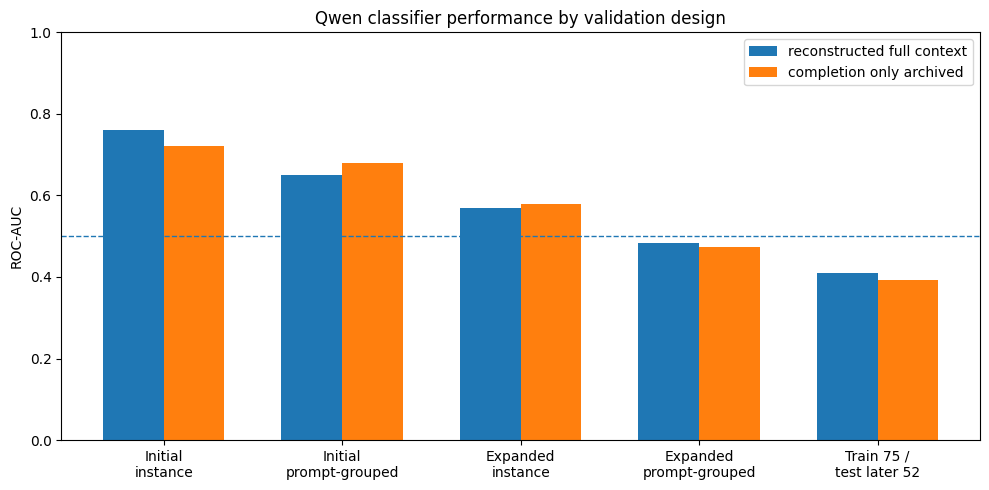

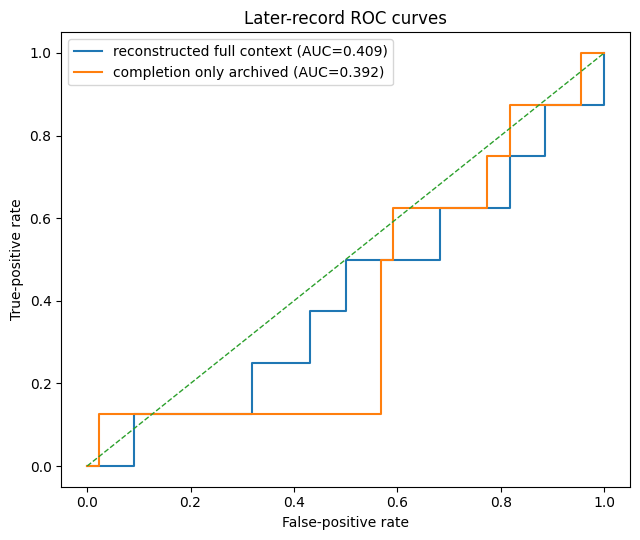

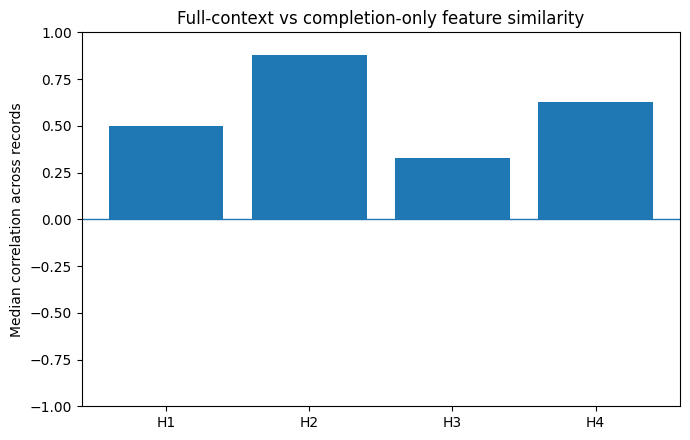

Input hashes recorded:
  full_context/qwen_compact_feature_manifest.json: 129cab2331d2dbd7bb72f96421311af35188c5f29cee5cf6e9bbb77b9b93f850
  full_context/qwen_full_context_features.csv: 91d715f59828b97ad75eb6baf10e85d0a63a077633462b5d1fd0ec930a2365fd
  full_context/qwen_full_context_features.npz: 1b5abdd20c0fa735824968993c132d8f7fd05eb5424564e98ff6cd0273359304
  full_context/qwen_prompt_attention_features.npz: b84862a41a5b53244c0764e6c230fd4608ad140a9a92b2702ba02059b215a2f7
  completion_only_features: 0ebb604fc968673a236368093a610ee96d80efb7d074b5dd4c0ea2d16366dbbd
# Qwen Priority-One Result Memo

## Reconstructed full-context replay

- Initial instance-CV AUC: **0.760**
- Expanded prompt-grouped AUC: **0.484**
- Train-75/test-later-52 AUC: **0.409**
- Later-set prompt-bootstrap 95% CI: **[0.318, 0.595]**

## Scope

These results characterize reconstructed full-context teacher-forced replay. They are not literal generation-time activations because the original generated token IDs and e

In [6]:
# -----------------------------------------------------------------------------
# Paired feature-space comparison
# -----------------------------------------------------------------------------
paired_feature_summary = pd.DataFrame()
paired_feature_per_feature = pd.DataFrame()
if completion_available:
    family_specs = {
        "H1": (0, 336),
        "H2": (336, 672),
        "H3": (672, 1008),
        "H4": (1008, 1009),
    }
    summary_rows = []
    per_feature_rows = []
    for family, (lo, hi) in family_specs.items():
        full_block = X_full[:, lo:hi]
        completion_block = X_completion[:, lo:hi]
        difference = full_block - completion_block
        flat_full = full_block.ravel()
        flat_completion = completion_block.ravel()
        overall_correlation = (
            float(np.corrcoef(flat_full, flat_completion)[0, 1])
            if np.std(flat_full) > 0 and np.std(flat_completion) > 0
            else np.nan
        )
        feature_correlations = []
        for local_feature in range(hi - lo):
            a = full_block[:, local_feature]
            b = completion_block[:, local_feature]
            correlation = (
                float(np.corrcoef(a, b)[0, 1])
                if np.std(a) > 0 and np.std(b) > 0
                else np.nan
            )
            feature_correlations.append(correlation)
            per_feature_rows.append({
                "family": family,
                "feature_index": lo + local_feature,
                "feature_name": feature_names[lo + local_feature],
                "correlation_across_records": correlation,
                "mean_full_context": float(a.mean()),
                "mean_completion_only": float(b.mean()),
                "mean_paired_difference": float((a - b).mean()),
                "mean_absolute_paired_difference": float(np.abs(a - b).mean()),
            })
        summary_rows.append({
            "family": family,
            "n_features": int(hi - lo),
            "overall_entrywise_correlation": overall_correlation,
            "median_featurewise_correlation": float(np.nanmedian(feature_correlations)),
            "mean_absolute_paired_difference": float(np.abs(difference).mean()),
            "root_mean_squared_paired_difference": float(np.sqrt(np.mean(difference ** 2))),
        })
    paired_feature_summary = pd.DataFrame(summary_rows)
    paired_feature_per_feature = pd.DataFrame(per_feature_rows)
    show(paired_feature_summary.round(4))

# -----------------------------------------------------------------------------
# Figures
# -----------------------------------------------------------------------------
figure_paths = []
evaluation_order = [
    "initial_instance_cv",
    "initial_prompt_grouped_cv",
    "expanded_instance_cv",
    "expanded_prompt_grouped_cv",
    "train75_test_later52",
]
plot_data = classifier_results.copy()
plot_data["evaluation"] = pd.Categorical(
    plot_data["evaluation"], categories=evaluation_order, ordered=True
)
plot_data = plot_data.sort_values(["evaluation", "condition"])

fig, ax = plt.subplots(figsize=(10, 5))
conditions_order = list(conditions.keys())
x = np.arange(len(evaluation_order))
width = 0.34 if len(conditions_order) == 2 else 0.55
for index, condition_name in enumerate(conditions_order):
    subset = (
        plot_data[plot_data["condition"] == condition_name]
        .set_index("evaluation")
        .reindex(evaluation_order)
    )
    offset = (index - (len(conditions_order) - 1) / 2) * width
    ax.bar(
        x + offset,
        subset["roc_auc"].to_numpy(),
        width=width,
        label=condition_name.replace("_", " "),
    )
ax.axhline(0.5, linestyle="--", linewidth=1)
ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Qwen classifier performance by validation design")
ax.set_xticks(x)
ax.set_xticklabels([
    "Initial\ninstance",
    "Initial\nprompt-grouped",
    "Expanded\ninstance",
    "Expanded\nprompt-grouped",
    "Train 75 /\ntest later 52",
])
ax.legend()
fig.tight_layout()
path = OUTPUT_DIR / "classifier_auc_comparison.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
figure_paths.append(path)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for condition_name in conditions:
    probabilities = condition_outputs[(condition_name, "train75_test_later52")]["probabilities"]
    fpr, tpr, _ = roc_curve(y[later_mask], probabilities)
    auc_value = roc_auc_score(y[later_mask], probabilities)
    ax.plot(
        fpr,
        tpr,
        label=f"{condition_name.replace('_', ' ')} (AUC={auc_value:.3f})",
    )
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate")
ax.set_title("Later-record ROC curves")
ax.legend()
fig.tight_layout()
path = OUTPUT_DIR / "later_record_roc_curves.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
figure_paths.append(path)

if completion_available:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(
        paired_feature_summary["family"],
        paired_feature_summary["median_featurewise_correlation"],
    )
    ax.set_ylim(-1, 1)
    ax.axhline(0, linewidth=1)
    ax.set_ylabel("Median correlation across records")
    ax.set_title("Full-context vs completion-only feature similarity")
    fig.tight_layout()
    path = OUTPUT_DIR / "paired_feature_family_correlations.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    figure_paths.append(path)

# -----------------------------------------------------------------------------
# Save all tables and arrays
# -----------------------------------------------------------------------------
tables_to_save = {
    "data_audit.csv": data_audit,
    "classifier_results.csv": classifier_results,
    "all_predictions.csv": all_predictions,
    "fold_assignments.csv": fold_assignments,
    "later_prompt_bootstrap.csv": bootstrap_results,
    "coefficient_stability.csv": coefficient_results,
    "record_level_head_tests.csv": record_level_head_tests,
    "record_level_test_summary.csv": record_level_summary,
    "prompt_aware_head_tests.csv": prompt_aware_head_tests,
    "prompt_aware_h4_tests.csv": prompt_aware_h4_tests,
    "prompt_visibility_sensitivity.csv": prompt_visibility_results,
    "prompt_attention_head_tests.csv": prompt_attention_head_tests,
    "leave_one_domain_out.csv": leave_one_domain_out,
    "positive_control_results.csv": positive_control_results,
    "paper_reference_completion_only.csv": paper_reference_completion_only,
}
if completion_available:
    tables_to_save.update({
        "paired_feature_summary.csv": paired_feature_summary,
        "paired_feature_per_feature.csv": paired_feature_per_feature,
        "paired_later_auc_difference.csv": paired_later_table,
    })
for filename, table in tables_to_save.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

for key, result in coefficient_matrices.items():
    condition_name, sample_name, design = key
    stem = f"{condition_name}_{sample_name}_{design}"
    np.save(OUTPUT_DIR / f"{stem}_coefficients.npy", result["coefficient_matrix"])
    pd.DataFrame(result["correlation_matrix"]).to_csv(
        OUTPUT_DIR / f"{stem}_coefficient_correlations.csv", index=False
    )

for condition_name, result in bootstrap_objects.items():
    np.save(
        OUTPUT_DIR / f"{condition_name}_later_prompt_bootstrap_auc.npy",
        result["scores"],
    )
if paired_later_bootstrap is not None:
    np.save(
        OUTPUT_DIR / "paired_later_auc_difference_bootstrap.npy",
        paired_later_bootstrap["differences"],
    )
# ============================================================
# Record input hashes for either Kaggle-extracted files or ZIP input
# ============================================================

input_hashes = {}

# Hash the original ZIP only when the ZIP fallback was used.
if "FULL_CONTEXT_ZIP" in globals() and FULL_CONTEXT_ZIP is not None:
    input_hashes["full_context_bundle_zip"] = sha256_file(
        FULL_CONTEXT_ZIP
    )

# In Kaggle's extracted-directory mode, hash each required input file.
else:
    for filename in sorted(BUNDLE_REQUIRED_FILES):
        file_path = EXTRACT_DIR / filename

        if not file_path.is_file():
            raise FileNotFoundError(
                f"Cannot hash missing bundle file: {file_path}"
            )

        input_hashes[f"full_context/{filename}"] = sha256_file(
            file_path
        )

# Hash the archived completion-only matrix when available.
if completion_available:
    input_hashes["completion_only_features"] = sha256_file(
        COMPLETION_ONLY_PATH
    )

print("Input hashes recorded:")
for name, digest in input_hashes.items():
    print(f"  {name}: {digest}")

summary = {
    "analysis": "Qwen reconstructed-full-context priority-one analysis",
    "seed": SEED,
    "fast_mode": FAST_MODE,
    "n_record_permutations": N_RECORD_PERMUTATIONS,
    "n_prompt_permutations": N_PROMPT_PERMUTATIONS,
    "n_bootstraps": N_BOOTSTRAPS,
    "environment": environment,
    "input_hashes": input_hashes,
    "input_manifest": manifest,
    "interpretation_boundary": (
        "Reconstructed full-context teacher-forced replay; not literal generation-time "
        "activation recovery. Original generated token IDs and exact model/tokenizer "
        "revisions were not archived."
    ),
    "classifier_results": json.loads(classifier_results.to_json(orient="records")),
    "bootstrap_results": json.loads(bootstrap_results.to_json(orient="records")),
    "coefficient_stability": json.loads(coefficient_results.to_json(orient="records")),
    "record_level_summary": json.loads(record_level_summary.to_json(orient="records")),
    "prompt_aware_h4": json.loads(prompt_aware_h4_tests.to_json(orient="records")),
}
if completion_available:
    summary["paired_later_auc_difference"] = json.loads(
        paired_later_table.to_json(orient="records")
    )
    summary["paired_feature_summary"] = json.loads(
        paired_feature_summary.to_json(orient="records")
    )
(OUTPUT_DIR / "qwen_priority1_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

# -----------------------------------------------------------------------------
# Concise TAE memo
# -----------------------------------------------------------------------------
def get_metric(condition: str, evaluation: str, metric: str) -> float:
    row = classifier_results[
        (classifier_results["condition"] == condition)
        & (classifier_results["evaluation"] == evaluation)
    ]
    if len(row) != 1:
        return float("nan")
    return float(row.iloc[0][metric])

full_later_auc = get_metric("reconstructed_full_context", "train75_test_later52", "roc_auc")
full_initial_auc = get_metric("reconstructed_full_context", "initial_instance_cv", "roc_auc")
full_expanded_grouped_auc = get_metric(
    "reconstructed_full_context", "expanded_prompt_grouped_cv", "roc_auc"
)
full_boot = bootstrap_results[
    bootstrap_results["condition"] == "reconstructed_full_context"
].iloc[0]

memo_lines = [
    "# Qwen Priority-One Result Memo",
    "",
    "## Reconstructed full-context replay",
    "",
    f"- Initial instance-CV AUC: **{full_initial_auc:.3f}**",
    f"- Expanded prompt-grouped AUC: **{full_expanded_grouped_auc:.3f}**",
    f"- Train-75/test-later-52 AUC: **{full_later_auc:.3f}**",
    f"- Later-set prompt-bootstrap 95% CI: **[{full_boot['ci_low']:.3f}, {full_boot['ci_high']:.3f}]**",
    "",
    "## Scope",
    "",
    (
        "These results characterize reconstructed full-context teacher-forced replay. "
        "They are not literal generation-time activations because the original generated "
        "token IDs and exact checkpoint revisions were not archived."
    ),
]

if completion_available:
    completion_later_auc = get_metric(
        "completion_only_archived", "train75_test_later52", "roc_auc"
    )
    point_difference = full_later_auc - completion_later_auc
    memo_lines.extend([
        "",
        "## Paired archived-condition comparison",
        "",
        f"- Completion-only later-record AUC under this rerun: **{completion_later_auc:.3f}**",
        f"- Full-context minus completion-only later-record AUC: **{point_difference:+.3f}**",
        (
            "- Paired prompt-bootstrap 95% CI for the AUC difference: "
            f"**[{paired_later_bootstrap['ci_low']:.3f}, {paired_later_bootstrap['ci_high']:.3f}]**"
        ),
        "",
        (
            "Because checkpoint/tokenizer revisions were not pinned in the original study, "
            "this difference should not be described as a pure causal context effect."
        ),
    ])

(OUTPUT_DIR / "TAE_QWEN_RESULT_MEMO.md").write_text(
    "\n".join(memo_lines), encoding="utf-8"
)
print("\n".join(memo_lines))

# -----------------------------------------------------------------------------
# Downloadable ZIP
# -----------------------------------------------------------------------------
RESULT_ZIP = OUTPUT_DIR.parent / "qwen_priority1_results_bundle.zip"
if RESULT_ZIP.exists():
    RESULT_ZIP.unlink()
with zipfile.ZipFile(
    RESULT_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=9,
) as archive:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(OUTPUT_DIR.parent))

print("Analysis complete.")
print("Result ZIP:", RESULT_ZIP)
print("ZIP size:", f"{RESULT_ZIP.stat().st_size / 1024**2:.2f} MiB")
print("Key memo:", OUTPUT_DIR / "TAE_QWEN_RESULT_MEMO.md")
